# torch practice 1 — tensor + ops harian
kerjakan cell `coba` dulu, baru buka cell `jawaban` (sudah collapsed). run: `python gen_torch_practice.py` untuk regenerate.

## A. tensor creation
**Q1.** buat tensor 0d scalar `3.0`, 1d vector `[1,2,3]`, 2d matrix `2x3` nol, 2d `2x3` random normal. print shape + dim tiap tensor.

In [2]:
import torch
q1 = torch.tensor([3.0], dtype=torch.float)
q12 = torch.tensor([1,2,3])
q13 = torch.zeros(2,3)
q14 = torch.randn(2,3)
print(q1, q12, q13, q14)

tensor([3.]) tensor([1, 2, 3]) tensor([[0., 0., 0.],
        [0., 0., 0.]]) tensor([[-1.8367,  1.7276, -1.2121],
        [ 0.2279,  2.8090, -0.0870]])


In [ ]:
# jawaban q1
import torch
s = torch.tensor(3.0)
v = torch.tensor([1., 2., 3.])
z = torch.zeros(2, 3)
r = torch.randn(2, 3)
for t in [s, v, z, r]:
    print(t.shape, t.dim(), t.numel())  # shape, jumlah dim, total elemen

**Q2.** buat tensor `arange(12)`, lalu reshape jadi `3x4` dan `2x2x3`. apa beda shape-nya?

In [3]:
q22 = torch.arange(12)
print(q22)
q22 = q22.reshape(3,4)
print(q22)
q22 = q22.reshape(2,2,3)
print(q22)


tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])
tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
tensor([[[ 0,  1,  2],
         [ 3,  4,  5]],

        [[ 6,  7,  8],
         [ 9, 10, 11]]])


In [ ]:
# jawaban q2
import torch
x = torch.arange(12)
print(x.reshape(3, 4))
print(x.reshape(2, 2, 3))  # total elemen tetap 12

**Q3.** buat batch image warna 4 buah `32x32`: shape yang benar untuk torch apa? buat juga versi gray. print keduanya.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-3.2690547..4.0844493].


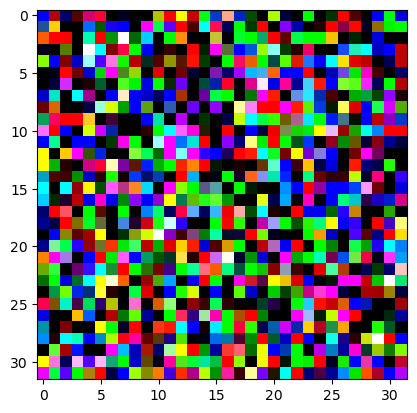

In [6]:
q3 = torch.randn(4, 3, 32,32)
q3grey = torch.randn(4,1,32,32)
import matplotlib.pyplot as plt
q31 = q3.permute(0, 2,3,1)
plt.imshow(q31[0])

In [ ]:
# jawaban q3
import torch
color = torch.randn(4, 3, 32, 32)  # N,C,H,W
print('color', color.shape)
gray = torch.randn(4, 1, 32, 32)  # N,1,H,W, channel=1 wajib ada untuk conv
print('gray', gray.shape)

**Q4.** dari numpy `float32` shape `(5, 224, 224, 3)` (NHWC dari cv2), ubah jadi tensor torch NCHW. lalu kembalikan ke numpy HWC untuk `imshow`.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-4.618464665979629..4.363924216769519].


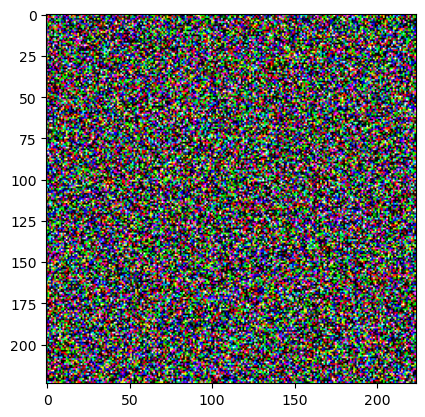

In [9]:
import numpy as np
npfloat = np.random.randn(5,224,224,3)
q4torch = torch.from_numpy(npfloat)
q4torch = q4torch.permute(0,3,1,2)
plt.imshow(q4torch.permute(0,2,3,1)[0])

In [ ]:
# jawaban q4
import torch, numpy as np
hwc = np.ones((5, 224, 224, 3), dtype=np.float32)
t = torch.from_numpy(hwc)  # masih NHWC
nchw = t.permute(0, 3, 1, 2)  # 5,3,224,224
print(nchw.shape)
back = nchw[0].permute(1, 2, 0).numpy()  # 224,224,3 untuk plt
print(back.shape)

**Q5.** buat tensor `ones(2,3)` dtype `float32` di cpu, lalu pindah ke device yang tersedia (`cuda` jika ada). cek device-nya.

In [10]:
q5 = torch.ones(2,3, dtype=torch.float32, device="cpu")
try:
    q5 = q5.device("cuda")
except:
    print("cuda not available")

cuda not available


In [ ]:
# jawaban q5
import torch
device = 'cuda' if torch.cuda.is_available() else 'cpu'
x = torch.ones(2, 3, dtype=torch.float32, device='cpu').to(device)
print(x.device, device)

## B. layout gray + newaxis
**Q6.** gray WAJIB `N,1,H,W` atau boleh `N,H,W`? coba `nn.Conv2d(1, 8, 3, padding=1)` dengan input `4,32,32` lalu dengan `4,1,32,32`. mana yang jalan?

In [ ]:
# tulis jawabanmu di sini


In [ ]:
# jawaban q6
import torch, torch.nn as nn
conv = nn.Conv2d(1, 8, 3, padding=1)
try:
    conv(torch.randn(4, 32, 32))
except Exception as e:
    print('NHW gagal:', type(e).__name__)  # conv wajib 4d
print(conv(torch.randn(4, 1, 32, 32)).shape)  # ok -> 4,8,32,32

**Q7.** tambah channel dim ke image gray `(32,32)` jadi `(1,32,32)` dengan 3 cara: `None`, `unsqueeze`, `reshape`.

In [ ]:
# tulis jawabanmu di sini


In [ ]:
# jawaban q7
import torch
x = torch.randn(32, 32)
print(x[None].shape)  # None = newaxis, cara numpy, hasil 1,32,32
print(x.unsqueeze(0).shape)  # cara torch paling jelas
print(x.reshape(1, 32, 32).shape)

**Q8.** dari `(4,32,32)` (N,H,W) jadi `(4,1,32,32)` (N,C,H,W) pakai `[:, None]`. lalu hilangkan lagi pakai `squeeze(1)`.

In [ ]:
# tulis jawabanmu di sini


In [ ]:
# jawaban q8
import torch
x = torch.randn(4, 32, 32)
y = x[:, None, :, :]  # None sisipkan dim di posisi 1 -> 4,1,32,32
print(y.shape)
print(y.squeeze(1).shape)  # buang dim channel -> 4,32,32

**Q9.** bedakan `squeeze()` vs `squeeze(1)` pada `x` shape `(4,1,32,32)`. kapan `squeeze()` berbahaya?

In [ ]:
# tulis jawabanmu di sini


In [ ]:
# jawaban q9
import torch
x = torch.randn(4, 1, 32, 32)
print(x.squeeze().shape)  # buang SEMUA dim ukuran 1 -> 4,32,32, ok di sini
z = torch.randn(1, 1, 8, 8)
print(z.squeeze().shape)  # jadi 8,8, batch ikut hilang, berbahaya
print(z.squeeze(1).shape)  # aman, hanya buang dim 1 -> 1,8,8

**Q10.** slicing: `x` shape `(4,3,32,32)`. ambil semua batch channel pertama saja. buktikan `x[:, :1]` sama dengan `x[:, :1, :, :]`.

In [ ]:
# tulis jawabanmu di sini


In [ ]:
# jawaban q10
import torch
x = torch.randn(4, 3, 32, 32)
a = x[:, :1]
b = x[:, :1, :, :]  # trailing : boleh dihilangkan
print(a.shape, b.shape, torch.equal(a, b))
print(x[0].shape, x[0, 1].shape)  # 3,32,32 lalu 32,32

## C. reshape / view / contiguous / transpose
**Q11.** apa itu contiguous (bahasa indonesia: bersebelahan)? buat `y = x.permute(0,2,3,1)`, cek `is_contiguous()`, lalu buat contiguous dan cek lagi.

In [ ]:
# tulis jawabanmu di sini


In [ ]:
# jawaban q11
import torch
x = torch.randn(4, 3, 32, 32)  # memori bersebelahan (contiguous)
y = x.permute(0, 2, 3, 1)  # hanya ubah stride, data tidak pindah
print(y.is_contiguous())  # False
print(y.contiguous().is_contiguous())  # True setelah copy ke layout baru

**Q12.** buktikan `view` gagal setelah `permute` tapi `reshape` sukses. print pesannya.

In [ ]:
# tulis jawabanmu di sini


In [ ]:
# jawaban q12
import torch
x = torch.randn(4, 3, 8, 8)
y = x.permute(0, 2, 3, 1)
try:
    y.view(4, -1)
except Exception as e:
    print('view gagal:', str(e)[:80])
print(y.reshape(4, -1).shape)  # reshape otomatis copy bila perlu

**Q13.** kapan pakai `view`? contoh: pastikan tensor contiguous dulu lalu `view` tanpa copy (hemat memori di training besar).

In [ ]:
# tulis jawabanmu di sini


In [ ]:
# jawaban q13
import torch
x = torch.randn(4, 3, 8, 8)
# skenario view: kita mau pastikan tidak ada copy diam-diam (hemat vram)
# kalau tensor sudah contiguous, view gratis tanpa copy
print(x.is_contiguous())
print(x.view(4, -1).shape)  # ok tanpa copy
# pola aman: x.contiguous().view(4, -1)

**Q14.** bedakan `.T` vs `.transpose(0,1)` vs `.permute(0,2,3,1)` pada batch `4,3,32,32`. mana yang untuk NCHW->NHWC?

In [ ]:
# tulis jawabanmu di sini


In [ ]:
# jawaban q14
import torch
x = torch.randn(4, 3, 32, 32)
print('T:', x.T.shape)  # balik semua dim -> 32,32,3,4, jarang dipakai
print('transpose:', x.transpose(0, 1).shape)  # tukar 2 dim -> 3,4,32,32
print('permute:', x.permute(0, 2, 3, 1).shape)  # bebas -> 4,32,32,3 NHWC

**Q15.** flatten image batch `(4,3,8,8)` jadi `(4,-1)` untuk `Linear`. berapa fitur per gambar? buat `Linear` yang cocok.

In [ ]:
# tulis jawabanmu di sini


In [ ]:
# jawaban q15
import torch, torch.nn as nn
x = torch.randn(4, 3, 8, 8)
f = x.reshape(4, -1)
print(f.shape)  # 4,192 karena 3*8*8=192
fc = nn.Linear(192, 10)
print(fc(f).shape)  # 4,10

**Q16.** transpose 2d: `m` shape `(4,5)`, buktikan `m.T` sama dengan `m.transpose(0,1)`.

In [ ]:
# tulis jawabanmu di sini


In [ ]:
# jawaban q16
import torch
m = torch.randn(4, 5)
print(m.T.shape, m.transpose(0, 1).shape)
print(torch.equal(m.T, m.transpose(0, 1)))

## D. cat vs stack / reduction / indexing
**Q17.** `cat` vs `stack` pada `a,b` shape `(2,3)`: cat dim=0, cat dim=1, stack dim=0. print semua shape.

In [ ]:
# tulis jawabanmu di sini


In [ ]:
# jawaban q17
import torch
a = torch.ones(2, 3)
b = torch.zeros(2, 3)
print('cat0', torch.cat([a, b], dim=0).shape)  # 4,3 gabung baris, mirip vstack
print('cat1', torch.cat([a, b], dim=1).shape)  # 2,6 gabung kolom, mirip hstack
print('stack0', torch.stack([a, b], dim=0).shape)  # 2,2,3 dim baru

**Q18.** high-dim: `x1,x2` shape `(4,3,8,8)`. cat dim=0 (tambah batch), cat dim=1 (tambah channel ala unet skip), stack dim=0. print shape.

In [ ]:
# tulis jawabanmu di sini


In [ ]:
# jawaban q18
import torch
x1 = torch.randn(4, 3, 8, 8)
x2 = torch.randn(4, 3, 8, 8)
print(torch.cat([x1, x2], dim=0).shape)  # 8,3,8,8
print(torch.cat([x1, x2], dim=1).shape)  # 4,6,8,8
print(torch.stack([x1, x2], dim=0).shape)  # 2,4,3,8,8

**Q19.** kapan `cat dim=1` dipakai? contoh unet skip connection: encoder `4,16,8,8` + decoder `4,16,8,8` -> berapa channel?

In [ ]:
# tulis jawabanmu di sini


In [ ]:
# jawaban q19
import torch
enc = torch.randn(4, 16, 8, 8)
dec = torch.randn(4, 16, 8, 8)
print(torch.cat([enc, dec], dim=1).shape)  # 4,32,8,8, channel berlipat

**Q20.** reduction: `x` shape `(4,3,8,8)`. hitung mean per-channel (`3`), max beserta index dim=1, dan sum total.

In [ ]:
# tulis jawabanmu di sini


In [ ]:
# jawaban q20
import torch
x = torch.randn(4, 3, 8, 8)
print(x.mean(dim=[0, 2, 3]).shape)  # 3, rata2 tiap channel
vals, idx = x.max(dim=1)
print(vals.shape, idx.shape)  # 4,8,8 keduanya
print(x.sum().item())  # scalar

**Q21.** kenapa `dim=[0,2,3]` berupa list? bandingkan `mean(dim=1)` vs `mean(dim=[0,2,3])` lalu `keepdim=True`.

In [ ]:
# tulis jawabanmu di sini


In [ ]:
# jawaban q21
import torch
x = torch.randn(4, 3, 8, 8)
print(x.mean(dim=1).shape)  # 4,8,8 buang channel saja
print(x.mean(dim=[0, 2, 3]).shape)  # 3, buang N,H,W sekaligus
print(x.mean(dim=[0, 2, 3], keepdim=True).shape)  # 1,3,1,1 bisa broadcast

**Q22.** normalisasi per-channel pakai `keepdim`: `(x - mean) / std`. cek mean hasil ~0.

In [ ]:
# tulis jawabanmu di sini


In [ ]:
# jawaban q22
import torch
x = torch.randn(4, 3, 8, 8)
mean = x.mean(dim=[0, 2, 3], keepdim=True)
std = x.std(dim=[0, 2, 3], keepdim=True)
xn = (x - mean) / std
print(xn.mean(dim=[0, 2, 3]))  # mendekati 0,0,0

**Q23.** dynamic indexing: `x[1,2,5,6]` hasilnya scalar? cek shape + `.item()`. lalu `x[1,2,5]` shape apa?

In [ ]:
# tulis jawabanmu di sini


In [ ]:
# jawaban q23
import torch
x = torch.randn(4, 3, 8, 8)
v = x[1, 2, 5, 6]
print(v.shape, v.item())  # torch.Size([]) scalar
print(x[1, 2, 5].shape)  # 8, satu baris
print(x[1].mean().item())  # valid

**Q24.** mini drill: dari `x` shape `(4,3,8,8)`, hasilkan `y` shape `(4,3)` berisi mean tiap (gambar, channel). satu baris saja.

In [ ]:
# tulis jawabanmu di sini


In [ ]:
# jawaban q24
import torch
x = torch.randn(4, 3, 8, 8)
y = x.mean(dim=[2, 3])  # buang H,W sisa N,C
print(y.shape)  # 4,3

**Q25.** gabungan akhir: flatten `(4,3,8,8)` -> linear `192->5` -> `argmax(dim=1)`. print logits dan pred shape.

In [ ]:
# tulis jawabanmu di sini


In [ ]:
# jawaban q25
import torch, torch.nn as nn
x = torch.randn(4, 3, 8, 8)
fc = nn.Linear(3*8*8, 5)
logits = fc(x.reshape(4, -1))
print(logits.shape)  # 4,5
print(logits.argmax(dim=1).shape)  # 4,